In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
REPO = "India-Demand-Forecasting-ML"
BRANCH = "feature/features-and-models"
if not os.path.exists(REPO):
    !git clone -b {BRANCH} https://github.com/tanishmaity03/India-Demand-Forecasting-ML.git
%cd {REPO}
!pip install -q holidays
sys.path.append(".")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from src.features import build_features, FEATURE_SETS
from src.evaluate import split_mask, SPLITS

sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)
Path("results/figures").mkdir(parents=True, exist_ok=True); Path("results/tables").mkdir(parents=True, exist_ok=True)

Cloning into 'India-Demand-Forecasting-ML'...
remote: Enumerating objects: 135, done.
remote: Counting objects: 100% (135/135), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 135 (delta 36), reused 121 (delta 24), pack-reused 0 (from 0)
Receiving objects: 100% (135/135), 20.56 MiB | 17.71 MiB/s, done.
Resolving deltas: 100% (36/36), done.
/content/India-Demand-Forecasting-ML


In [2]:
df = pd.read_csv("data/processed/india_demand_weather.csv", parse_dates=["datetime"])
ds1 = build_features(df, 1, "full")
ds24 = build_features(df, 24, "full")
print("h=1 :", ds1.X.shape, "| h=24:", ds24.X.shape)
print(list(ds24.X.columns))
ds24.X.head()

h=1 : (46392, 34) | h=24: (46369, 33)
['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_24', 'lag_48', 'lag_168', 'same_hour_last_week', 'roll_mean_24', 'roll_std_24', 'roll_max_24', 'roll_min_24', 'weekly_growth', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos', 'is_weekend', 'is_holiday', 'covid_lockdown', 'temp_c_target', 'rh_pct_target', 'dewpoint_c_target', 'wind_ms_target', 'solar_wm2_target', 'precip_mm_target', 'cdd_target', 'temp_roll24', 'temp_delta']


,lag_0,lag_1,lag_2,lag_3,lag_6,lag_12,lag_24,lag_48,lag_168,same_hour_last_week,roll_mean_24,roll_std_24,roll_max_24,roll_min_24,weekly_growth,hour_sin,hour_cos,dow_sin,dow_cos,doy_sin,doy_cos,is_weekend,is_holiday,covid_lockdown,temp_c_target,rh_pct_target,dewpoint_c_target,wind_ms_target,solar_wm2_target,precip_mm_target,cdd_target,temp_roll24,temp_delta
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-01-14 23:00:00,0.865783,0.902605,0.948044,0.985568,1.012631,1.087545,0.870087,0.903248,0.891035,0.890894,0.971973,0.104062,1.112461,0.801107,1.009600,-0.258819,0.965926,0.781831,0.623490,0.254671,0.967028,0,0,0,16.69558,74.7733,12.01254,2.491318,0.0,0.0,0.0,19.624951,-0.53896
2019-01-15 00:00:00,0.834107,0.865925,0.902752,0.948200,1.038820,1.066818,0.838449,0.866758,0.861590,0.863848,0.971951,0.104325,1.112643,0.801238,1.009358,0.000000,1.000000,0.974928,-0.222521,0.271234,0.962513,0,0,0,17.20784,71.5686,11.65430,2.199174,0.0,0.0,0.0,19.610640,0.27042
2019-01-15 01:00:00,0.814453,0.834247,0.866069,0.902903,1.034804,1.037704,0.817752,0.844673,0.842535,0.845077,0.971976,0.104556,1.112829,0.801372,1.009113,0.258819,0.965926,0.974928,-0.222521,0.271234,0.962513,0,0,0,16.10264,76.8658,11.99092,2.334921,0.0,0.0,0.0,19.596550,-0.59321
2019-01-15 02:00:00,0.801747,0.814607,0.834404,0.866233,0.986080,1.011372,0.804485,0.833190,0.833460,0.831430,0.972046,0.104768,1.113039,0.801523,1.008816,0.500000,0.866025,0.974928,-0.222521,0.271234,0.962513,0,0,0,16.38369,75.2254,11.67194,2.035046,0.0,0.0,0.0,19.589780,-0.11801
2019-01-15 03:00:00,0.803414,0.801883,0.814745,0.834545,0.948697,1.001894,0.801658,0.830830,0.831822,0.829265,0.972283,0.104662,1.113228,0.801883,1.008533,0.707107,0.707107,0.974928,-0.222521,0.271234,0.962513,0,0,0,15.54080,78.5446,11.66276,2.178298,0.0,0.0,0.0,19.588448,-0.75050


In [3]:
def group(name):
    if name.startswith(("lag_", "same_hour")): return "Demand lag"
    if name.startswith("roll_") or name == "weekly_growth": return "Rolling demand"
    if name.endswith(("_sin", "_cos")) or name == "is_weekend": return "Calendar"
    if name in ("is_holiday", "covid_lockdown"): return "Event"
    return "Weather"

catalog = pd.DataFrame({"feature": ds24.X.columns, "group": [group(c) for c in ds24.X.columns]})
catalog.to_csv("results/tables/feature_catalog.csv", index=False)
catalog["group"].value_counts()

,count
group,
Demand lag,10
Weather,9
Calendar,7
Rolling demand,5
Event,2


In [4]:
rows = []
for h, ds in ((1, ds1), (24, ds24)):
    for part in ("train", "val", "test"):
        rows.append({"horizon_h": h, "split": part, "rows": int(split_mask(ds.target_time, part).sum())})
sizes = pd.DataFrame(rows).pivot(index="horizon_h", columns="split", values="rows")[["train", "val", "test"]]
sizes.to_csv("results/tables/split_sizes.csv")
print(SPLITS); sizes

{'train': ('2019-01-01', '2021-12-31'), 'val': ('2022-01-01', '2022-12-31'), 'test': ('2023-01-01', '2024-04-30')}


split,train,val,test
horizon_h,,,
1,25968,8760,11664
24,25945,8760,11664


In [5]:
!python -m unittest discover -s tests -t . -v

test_baselines_are_known_at_origin (tests.test_features.FeatureTests.test_baselines_are_known_at_origin) ... ok
test_no_future_demand_in_features (tests.test_features.FeatureTests.test_no_future_demand_in_features)
Changing demand after time t0 must not change any feature row with origin <= t0. ... ok
test_no_missing_values (tests.test_features.FeatureTests.test_no_missing_values) ... ok
test_target_alignment (tests.test_features.FeatureTests.test_target_alignment) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.311s

OK


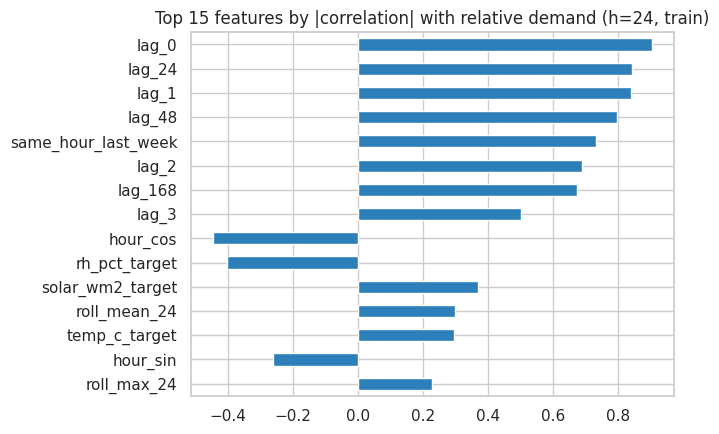

count    46369.000
mean         1.001
std          0.087
min          0.686
25%          0.945
50%          1.006
75%          1.063
max          1.276
Name: national, dtype: float64


In [6]:
tr = split_mask(ds24.target_time, "train")
corr = ds24.X[tr].corrwith(ds24.y_rel[tr]).sort_values(key=abs, ascending=False).head(15)
plt.figure(figsize=(7, 4.5))
corr.iloc[::-1].plot.barh(color="#2c7fb8")
plt.title("Top 15 features by |correlation| with relative demand (h=24, train)")
plt.tight_layout()
plt.savefig("results/figures/04_feature_target_correlation.png", dpi=150)
plt.show()
print(ds24.y_rel.describe().round(3))

## Feature engineering decisions
- Demand features use only data up to the forecast origin; unit tests confirm future demand never changes past features.
- Calendar and holiday features describe the target time (known in advance). Indian public holidays come from the `holidays` package.
- Weather features use actual weather at the target time as a stand-in for a weather forecast (optimistic assumption).
- Demand features and target are divided by the previous 168-hour mean so models predict relative demand;
  this avoids tree models being capped by the training demand range despite year-on-year growth.
- Splits are chronological and defined on target time: train 2019-2021, validation 2022, test Jan 2023 - Apr 2024.
  The test set is not used until final evaluation.

In [8]:
!zip -qr /content/day3_features_outputs.zip results
from google.colab import files
files.download("/content/day3_features_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>